<a href="https://colab.research.google.com/github/priyansh-commits/Deep_Learning/blob/main/stock_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
!pip -q install yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization

import warnings
warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

Price            Close
Date                  
2015-01-01  189.125381
2015-01-02  188.624802
2015-01-05  186.558685
2015-01-06  178.091812
2015-01-07  181.968491
(2716, 1)


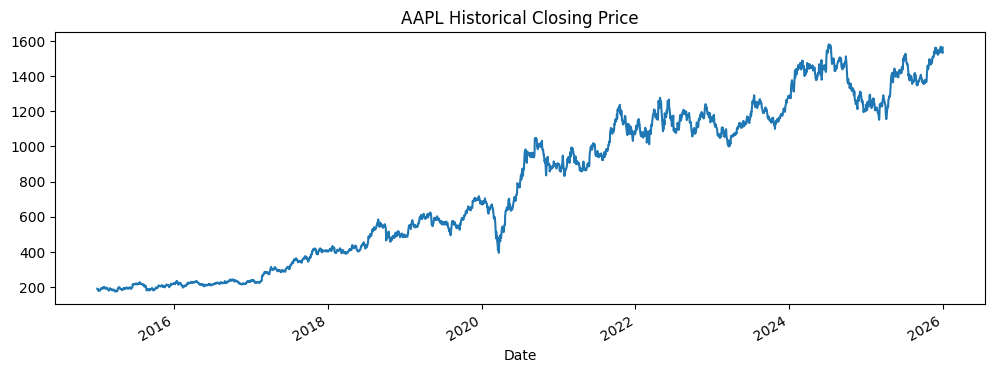

In [88]:
df = yf.download(
    "RELIANCE.NS",
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

# Handle yfinance's possible MultiIndex columns
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[["Close"]].dropna()

print(df.head())
print(df.shape)

df["Close"].plot(figsize=(12, 4), title="AAPL Historical Closing Price")
plt.show()

In [89]:
prices = df[["Close"]].values

split_idx = int(len(prices) * 0.8)

train_prices = prices[:split_idx]
test_prices = prices[split_idx:]

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_prices)
test_scaled = scaler.transform(test_prices)

print("Train samples:", len(train_scaled))
print("Test samples:", len(test_scaled))

Train samples: 2172
Test samples: 544


In [90]:
days=60

In [91]:
def create_sequences(data, window=60):
    X, y = [], []

    for i in range(window, len(data)):
        X.append(data[i-window:i, 0])
        y.append(data[i, 0])

    X = np.array(X)
    y = np.array(y)

    return X.reshape(-1, window, 1), y

X_train, y_train = create_sequences(train_scaled)


test_context = np.vstack([train_scaled[-days:], test_scaled])
X_test, y_test = create_sequences(test_context)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(2112, 60, 1) (2112,)
(544, 60, 1) (544,)


In [92]:

def build_model(model_type):
    model = Sequential()

    if model_type == "SimpleRNN":
        model.add(SimpleRNN(
            32,
            # return_sequences=True,
            input_shape=(days, 1)
        ))


    elif model_type == "LSTM":
        model.add(LSTM(
            32,
            # return_sequences=True,
            input_shape=(days, 1)
        ))


    elif model_type == "GRU":
        model.add(GRU(
            32,
            # return_sequences=True,
            input_shape=(days, 1)
        ))


    else:
        raise ValueError(f"Unknown model type: {model_type}")

    model.add(Dropout(0.15))
    model.add(Dense(16, activation="relu"))
    model.add(Dense(1))

    model.compile(optimizer="adam", loss="mse")

    return model

In [93]:
models = {}
histories = {}
predictions = {}

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.001,
    restore_best_weights=True
)

for name in ["SimpleRNN", "LSTM", "GRU"]:
    print(f"\nTraining {name}...")

    model = build_model(name)

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        shuffle=False,
        callbacks=[early_stop],
        verbose=1
    )

    models[name] = model
    histories[name] = history

    # Generate predictions from THIS model
    pred_scaled = model.predict(X_test, verbose=0)

    print(name, "raw prediction shape:", pred_scaled.shape)

    # Convert scaled values back to actual stock prices
    pred_scaled = pred_scaled.reshape(-1, 1)
    predictions[name] = scaler.inverse_transform(
        pred_scaled
    ).ravel()

    print(name, "final prediction count:", len(predictions[name]))


Training SimpleRNN...
Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0080 - val_loss: 0.0072
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0024 - val_loss: 0.0014
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0020 - val_loss: 0.0028
Epoch 5/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0015 - val_loss: 0.0023
Epoch 6/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0015 - val_loss: 0.0023
SimpleRNN raw prediction shape: (544, 1)
SimpleRNN final prediction count: 544

Training LSTM...
Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0027 - val_loss: 0.0011
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0057 - val_loss: 0.0023
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0018 - val_loss: 0.0020
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0016 - val_loss: 9.2853e-04
Epoch 5/30
53/53 ━━━━━━━━━

In [94]:
print("Actual count:", len(actual))

for name, pred in predictions.items():
    print(name, len(pred))

Actual count: 554
SimpleRNN 544
LSTM 544
GRU 544


In [95]:
actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

results = []

for name, pred in predictions.items():
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results).sort_values("MAE")

print(results_df)

       Model         MAE        RMSE
1       LSTM   90.468594  101.954339
0  SimpleRNN  108.734242  119.476590
2        GRU  114.023394  122.511118


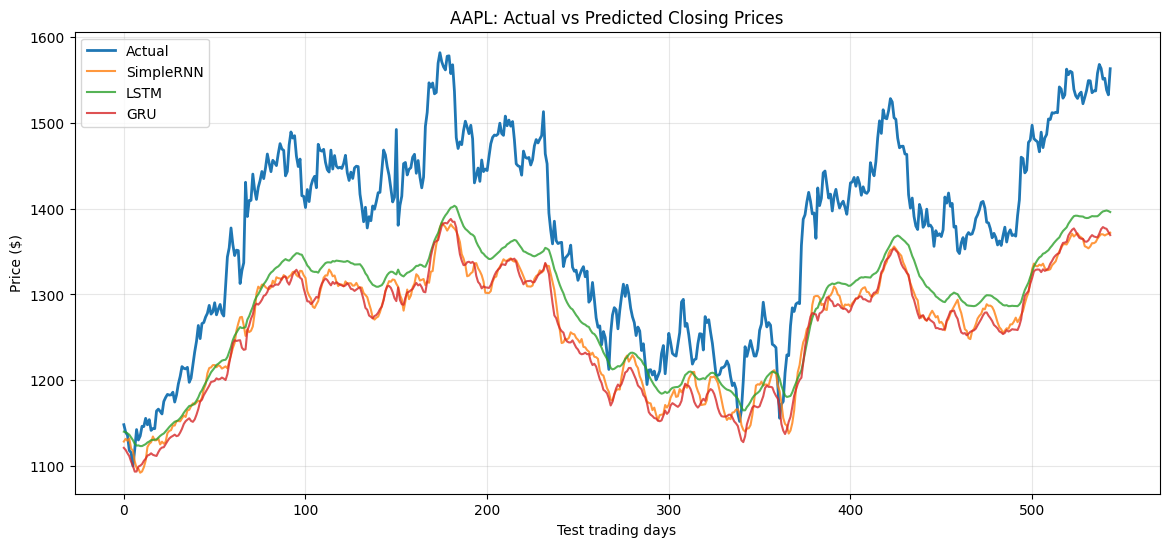

In [96]:
plt.figure(figsize=(14, 6))

plt.plot(actual, label="Actual", linewidth=2)

for name, pred in predictions.items():
    plt.plot(pred, label=name, alpha=0.8)

plt.title("AAPL: Actual vs Predicted Closing Prices")
plt.xlabel("Test trading days")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

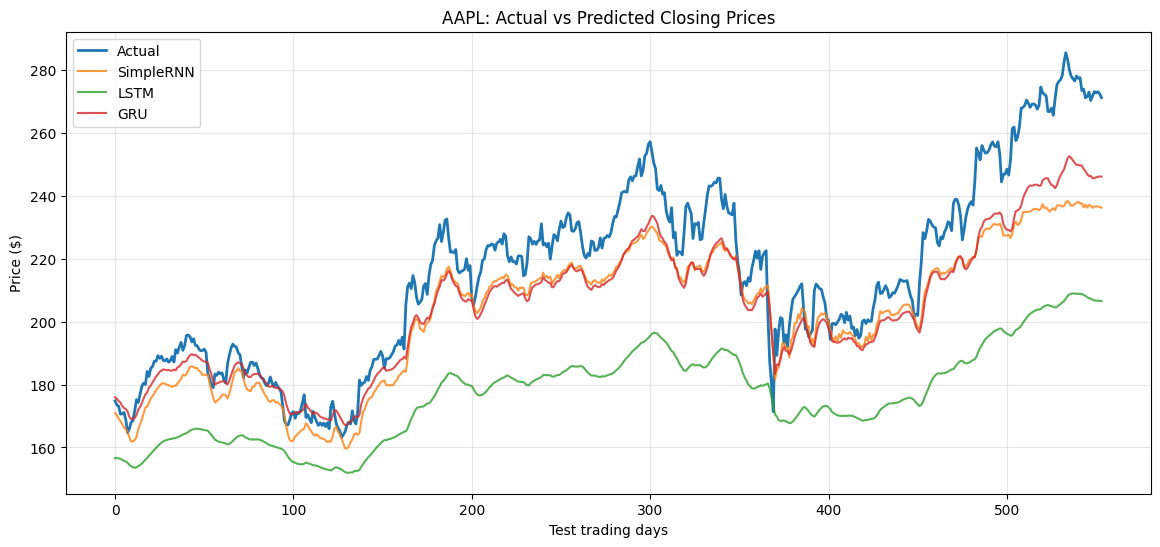

In [97]:
close_prices = df["Close"].to_numpy(dtype=float)

train_close = close_prices[:split_idx]
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# 1. Create the naive baseline
# Predict that tomorrow's close = today's close
naive_pred = np.concatenate([
    train_close[-1:],
    actual[:-1]
])

# 2. Add baseline to your existing predictions
all_predictions = predictions.copy()
all_predictions["Naive Baseline"] = naive_pred

# 3. Compare all models
results = []

for name, pred in all_predictions.items():
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("MAE").to_string(index=False))

         Model        MAE       RMSE
Naive Baseline  12.884843  17.915273
          LSTM  90.468594 101.954339
     SimpleRNN 108.734242 119.476590
           GRU 114.023394 122.511118


**FOR 30 DAYS**


```
         Model       MAE      RMSE
Naive Baseline  2.448790  3.625660
           GRU  3.152632  4.489642
          LSTM 24.301933 27.537755
     SimpleRNN 28.474677 33.081692
```


```


Actual first 5: [187.08908081 187.66207886 188.93658447 187.14836121 191.09028625]
Naive first 5: [176.33505249 187.08908081 187.66207886 188.93658447 187.14836121]
GRU first 5: [189.52892 189.1151  189.13033 189.74525 189.30013]
```






**FOR 60 DAYS**
```
     Model       MAE      RMSE
Naive Baseline  2.383065  3.525843
           GRU 11.473411 14.031575
     SimpleRNN 12.921555 16.024301
          LSTM 38.046757 41.011687
```


```
Actual first 5: [174.78599548 173.49351501 173.11857605 170.57299805 170.69136047]
Naive first 5: [176.33505249 174.78599548 173.49351501 173.11857605 170.57299805]
GRU first 5: [175.9444  175.45439 174.77417 174.23096 173.1699 ]
```


naive prediction were better than all neural networks just so it is complext doesnt mean it si better


In [98]:
print("Actual first 5:", actual[:5])
print("Naive first 5:", naive_pred[:5])
print("GRU first 5:", predictions["GRU"][:5])

print("Lengths:")
print("Actual:", len(actual))
print("Naive:", len(naive_pred))
print("GRU:", len(predictions["GRU"]))

Actual first 5: [1148.1541748  1139.33544922 1135.85253906 1118.11633301 1115.52258301]
Naive first 5: [1163.59301758 1148.1541748  1139.33544922 1135.85253906 1118.11633301]
GRU first 5: [1121.1753 1118.7004 1114.879  1111.4823 1105.1105]
Lengths:
Actual: 544
Naive: 544
GRU: 544


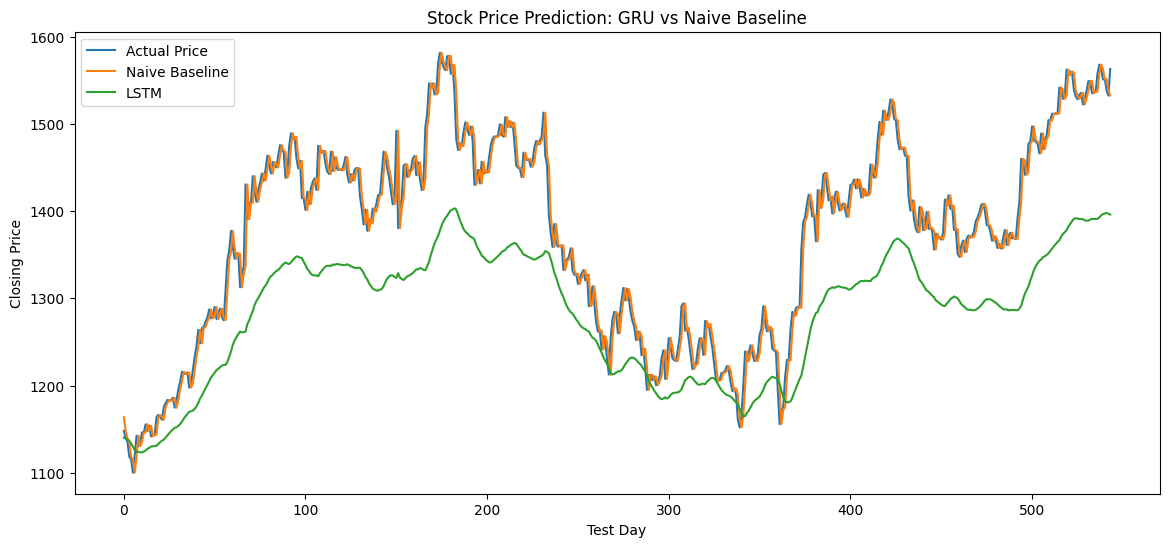

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(actual, label="Actual Price")
plt.plot(naive_pred, label="Naive Baseline")
plt.plot(predictions["LSTM"], label="LSTM")

plt.title("Stock Price Prediction: GRU vs Naive Baseline")
plt.xlabel("Test Day")
plt.ylabel("Closing Price")
plt.legend()
plt.show()